In [2]:
import numpy as np 
import matplotlib.pyplot as plt 

In [3]:
datos = np.genfromtxt('datos-01.txt')
x0 = datos[:,0]
y0 = datos[:,1]

N = len(y0)-1
h = x0[1]-x0[0]

M = 4*np.eye(N-1)+np.eye(N-1,k=1)+np.eye(N-1,k=-1)

Y = 3/h**2*(y0[:-2] -2*y0[1:-1] +y0[2:])

Bsolve = np.linalg.solve(M,Y)
B = np.zeros(N+1)
B[1:-1]=Bsolve
print(B)


[ 0.         -3.64285714  2.57142857 -0.64285714  0.        ]


In [4]:
print(y0[:-2], y0[1:-1], y0[2:])
print(y0)

[1. 4. 3.] [4. 3. 4.] [3. 4. 5.]
[1. 4. 3. 4. 5.]


In [5]:
print(M)

[[4. 1. 0.]
 [1. 4. 1.]
 [0. 1. 4.]]


In [7]:
a = np.zeros(N+1)
a[:-1] = (B[1:]-B[:-1])/(3*h)
print(a)

[-1.21428571  2.07142857 -1.07142857  0.21428571  0.        ]


In [ ]:
c = np.zeros(N+1)
c[:-1] = 1/h*(y0[1:]-y0[:-1])-h/3*(B[1:]+2*B[:-1])
print(c)

[ 4.21428571 -4.28571429  2.92857143  0.57142857  0.        ]


In [ ]:
c[-1] = c[-2]+3*a[-2]*h**2+2*B[-2]*h
print(c)
a[-1] = (h*c[-1]-y0[0]+y0[-1])/2*h**3
print(a)

[ 4.21428571 -4.28571429  2.92857143  0.57142857 -0.07142857]
[-1.21428571  2.07142857 -1.07142857  0.21428571  1.96428571]


In [10]:
B[-1]=-3*h*a[-1] #Aqui puede haber un error ya que no pide guardar el valor de B final sino lo ocupamos para calcular los coeficientes
print(B) 

[ 0.         -3.64285714  2.57142857 -0.64285714 -0.        ]


In [ ]:
xx = np.linspace(x0[0],x0[-1],100)  
S= np.zeros(N)
for n in range(N):
    S=a[n]*(xx-x0[n])**3+B[n]*(xx-x0[n])**2+c[n]*(xx-x0[n])+y0[n] #Error malo
print(S)

[43.75       42.04438805 40.38740794 38.7783671  37.21657297 35.70133297
 34.23195453 32.80774509 31.42801206 30.0920629  28.79920501 27.54874584
 26.3399928  25.17225335 24.04483489 22.95704487 21.90819071 20.89757984
 19.9245197  18.9883177  18.08828129 17.2237179  16.39393494 15.59823986
 14.83594008 14.10634303 13.40875614 12.74248685 12.10684258 11.50113076
 10.92465883 10.3767342   9.85666432  9.36375661  8.89731851  8.45665743
  8.04108082  7.6498961   7.2824107   6.93793206  6.61576759  6.31522474
  6.03561093  5.77623359  5.53640016  5.31541805  5.11259471  4.92723756
  4.75865403  4.60615156  4.46903756  4.34661948  4.23820474  4.14310077
  4.060615    3.99005487  3.9307278   3.88194121  3.84300255  3.81321925
  3.79189872  3.7783484   3.77187573  3.77178813  3.77739303  3.78799786
  3.80291005  3.82143704  3.84288624  3.8665651   3.89178104  3.91784149
  3.94405388  3.96972564  3.99416421  4.016677    4.03657146  4.05315501
  4.06573508  4.0736191   4.0761145   4.07252871  4

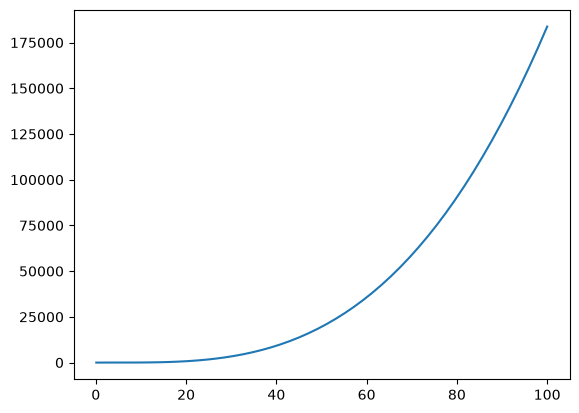

In [ ]:
plt.plot(xx,S)